# 10 领取优惠券：用户券、兑换码与并发安全

## 本章范围与资料来源

第 09 章完成了优惠券配置和发放，本章进入用户端：展示可领取的手动券、创建用户券、用兑换码领取、查询我的优惠券，并处理并发下的超发、超领和事务失效。

| 来源 | 本章使用的内容 |
| --- | --- |
| [网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj)，提取码 `w7bj` | `day10-领取优惠券/讲义/day10-领取优惠券.pptx`，共 43 页；核对 4 个接口、用户券模型、Bitmap 兑换、超卖、锁边界和事务失效；嵌入第 14、32 页原图 |
| 网盘 `day10-领取优惠券/资料` | 看到 `enums`、`query`、`vo`、`tj_promotion.sql`，以及 `jmeter` 目录中的 `Jmeter快速入门.md`、`领取优惠券.jmx`、`userInfo.txt`、`exchangeCode.txt`、JMeter 5.4.1 压缩包；尝试 Markdown 预览未取得完整正文；Java / SQL / 压测附件未取得全文 |
| [第三方公开转载：Day10-领取优惠券](https://imousse.github.io/cswiki/src/project/college/10-%E9%A2%86%E5%8F%96%E4%BC%98%E6%83%A0%E5%88%B8) | 补充服务代码、拦截器、并发分析、事务代理和练习；转载中的代码有省略或语法笔误，本文标出可直接采用的约束与需要改进的地方 |

阅读日期：2026-10-09。**课件方案**表示材料明确展示的做法；**整理示例**用于解释主线；**补充 / 改进示例**补足多实例部署、失败恢复和安全边界。本 Notebook 全部为 Markdown，不运行课程服务、JMeter、数据库或 Redis。

## 优惠券模板和用户券不是同一个实体

运营后台配置的是优惠券模板 `coupon`，它描述规则和库存，不属于任何用户。用户点击领取后，系统生成一条 `user_coupon`，它才代表某个用户拥有一张可以使用的券。

```text
coupon（规则模板） 1 ───── N user_coupon（用户持有记录）
        name、折扣规则             user_id、有效期、使用状态
```

同一模板可以产生很多用户券；用户券除了保存 `user_id + coupon_id` 这组关系，还要保存领取后的有效期、使用时间和当前状态。兑换码也是领取入口，它先指向优惠券模板，再创建用户券。

## 用户券表的字段和状态

课件 SQL 的核心表是 `user_coupon`。转载实体截图明确使用 `@TableId(value="id", type=IdType.ASSIGN_ID)`，用户券 ID 由 MyBatis-Plus 分配雪花 ID；状态使用 `UserCouponStatus` 枚举，网盘 `enums` 目录也有同名 Java 文件。

| 字段 | 含义 |
| --- | --- |
| `id` | 用户券 ID，建议 `BIGINT` / 雪花 ID |
| `user_id`, `coupon_id` | 所有者和优惠券模板 |
| `term_begin_time`, `term_end_time` | 这张用户券真正可使用的时间段 |
| `used_time` | 核销时间，未使用时为空 |
| `status` | 1 未使用、2 已使用、3 已失效 |
| `create_time`, `update_time` | 领取和修改时间 |

```sql
CREATE TABLE user_coupon (
  id BIGINT NOT NULL AUTO_INCREMENT,
  user_id BIGINT NOT NULL,
  coupon_id BIGINT NOT NULL,
  term_begin_time DATETIME NULL,
  term_end_time DATETIME NOT NULL,
  used_time DATETIME NULL,
  status TINYINT NOT NULL DEFAULT 1,
  PRIMARY KEY (id),
  KEY idx_coupon (coupon_id),
  KEY idx_user_coupon (user_id, coupon_id)
);
```

这是根据已读转载 DDL 整理的关键列，省略了创建 / 更新时间等已在字段表中列出的内容。DDL 保留 `AUTO_INCREMENT`，`ASSIGN_ID` 则显式插入生成的 ID，两种生成职责应统一，不能把自动生成值与雪花 ID 随意混用。`(user_id,coupon_id)` 不能简单设为唯一，因为 `user_limit` 可能允许同一用户领取多张。

## 本章的四个用户端接口

| 能力 | 方法与路径 | 登录 | 说明 |
| --- | --- | --- | --- |
| 查询正在发放的手动券 | `GET /coupons/list` | 可匿名查看 | 服务端固定筛选进行中 + 手动领取 |
| 手动领取 | `POST /user-coupons/{id}/receive` | 必须登录 | `{id}` 是优惠券模板 ID |
| 兑换码领取 | `POST /user-coupons/{code}/exchange` | 必须登录 | `{code}` 解析后定位目标券 |
| 查询我的优惠券 | `GET /user-coupons/page` | 必须登录 | `pageNo`、`pageSize`、`status` |

用户 ID 从登录上下文获取，前端不应传一个可伪造的 `userId`。路径参数要进行格式、长度和权限校验，兑换码也不要写入普通访问日志。

## 发放列表只展示可手动领取的券

`GET /coupons/list` 是无参接口，后台固定加上 `status=ISSUING` 和 `obtain_way=PUBLIC`（手动领取）。兑换码券不会出现在这个列表，用户通过输入码进入另一条流程。

列表项除了优惠券基本信息，还要给前端三个结果：

| 字段 | 计算方式 | 前端表现 |
| --- | --- | --- |
| `available` | `issue_num < total_num` 且当前用户已领数量 `< user_limit` | 真时可点击领取，假时显示已领完 / 不可领取 |
| `received` | 课程：当前用户存在一张状态为未使用的该券 | 提示去使用；时间过期等边界需另处理 |
| 折扣信息 | 类型、门槛、优惠值、上限 | 组合成人类可读的优惠文案 |

未登录时按“未持有”设置 `received=false`，`available` 可按库存展示，点击领取再引导登录。对已登录用户，限领统计包含未使用、已使用和已失效记录：课程规则限制累计领取次数，使用或过期不会恢复额度。`received` 和 `available` 可同时为真，前端须约定优先级；`available=false` 也可能是本人额度用完，不能一律解释为全站已抢完。

库存与用户已领数量仍由服务端重新判断，列表只是展示状态。补充方案用状态和当前时间排除已过期的“未使用”券；若固定有效期尚未开始，要显示可用日期，不能把“未使用”直接等同于现在可用。

## 统计用户领取数量时要避免 N+1 查询

**课件方案**先查出所有进行中的券，再一次性按当前用户和券 ID 集合查询 `user_coupon`，在内存中分组：一组统计总领取次数，一组只统计未使用次数。下面片段用于“券集合非空且用户已登录”的分支。

```java
List<Long> couponIds = coupons.stream()
    .map(Coupon::getId).collect(Collectors.toList());
List<UserCoupon> mine = userCouponService.lambdaQuery()
    .eq(UserCoupon::getUserId, userId)
    .in(UserCoupon::getCouponId, couponIds)
    .list();

Map<Long, Long> issued = mine.stream().collect(
    Collectors.groupingBy(UserCoupon::getCouponId, Collectors.counting()));
Map<Long, Long> unused = mine.stream()
    .filter(uc -> uc.getStatus() == UserCouponStatus.UNUSED)
    .collect(Collectors.groupingBy(UserCoupon::getCouponId, Collectors.counting()));
```

券数量很多时，返回前只查询必要字段或让数据库直接 `GROUP BY coupon_id`；不要为了每张券再发一次 SQL。缓存只能优化展示，不能替代领取时的库存和限领判断。

## 匿名访问与登录拦截器的分工

促销服务引入 `tj-auth-resource-sdk` 后，会有两个不同职责的 Spring MVC 拦截器：

| 拦截器 | 行为 | 本章用途 |
| --- | --- | --- |
| `UserInfoInterceptor` | 尝试从请求头读取用户 ID，写入 `UserContext`，读取失败也放行 | 所有接口都可获得“有则有、无则空”的用户上下文 |
| `LoginAuthInterceptor` | 用户未登录时拦截并返回错误 | 只保护领券、兑换和“我的优惠券” |

登录拦截是否启用由 `tj.auth.resource.enable` 控制，具体路径由 `includeLoginPaths` 和 `excludeLoginPaths` 控制。要让未登录用户浏览列表，应把 `/coupons/list` 放进放行配置；两个拦截器有先后关系，登录拦截依赖前一个拦截器已经设置 `UserContext`。

## 只放行公开列表，保留领取鉴权

如果为了匿名浏览直接关闭整个促销服务的登录校验，领券、兑换和私人列表也可能失去保护。应精确配置公开路径：

```yaml
# 整理示例：属性绑定对应 ResourceAuthProperties
tj:
  auth:
    resource:
      enable: true
      exclude-login-paths:
        - /coupons/list
```

```java
Long userId = UserContext.getUser();
List<UserCoupon> mine = Collections.emptyList();
if (userId != null && !couponIds.isEmpty()) {
    mine = queryUserCoupons(userId, couponIds);
}
// 匿名分支使用空领取计数，不把 null 当成真实用户查询私人记录
```

微服务请求头中的用户 ID 必须来自受信任网关验证后的身份，网关覆盖外部伪造的身份头，服务限制直接访问。请求结束时拦截器清理 `UserContext`，防止线程池复用串用身份。公开路径的“无需登录”与私人写接口的权限检查是两件独立配置。

## 手动领取的业务流程

```text
读取 coupon
  ↓ 存在且状态为进行中、当前时间在领取窗口
检查库存 issue_num < total_num
  ↓
检查当前用户已领取数量 < user_limit
  ↓
原子占用库存 +1
  ↓
根据 term_days 或固定时间段创建 user_coupon
```

库存和用户限领是两种不同的并发资源：库存是所有用户共享的一行计数，适合用数据库条件更新；用户限领是“某用户 + 某张券”的临时统计，需要让同一用户的检查和插入在可见的事务边界内串行化。

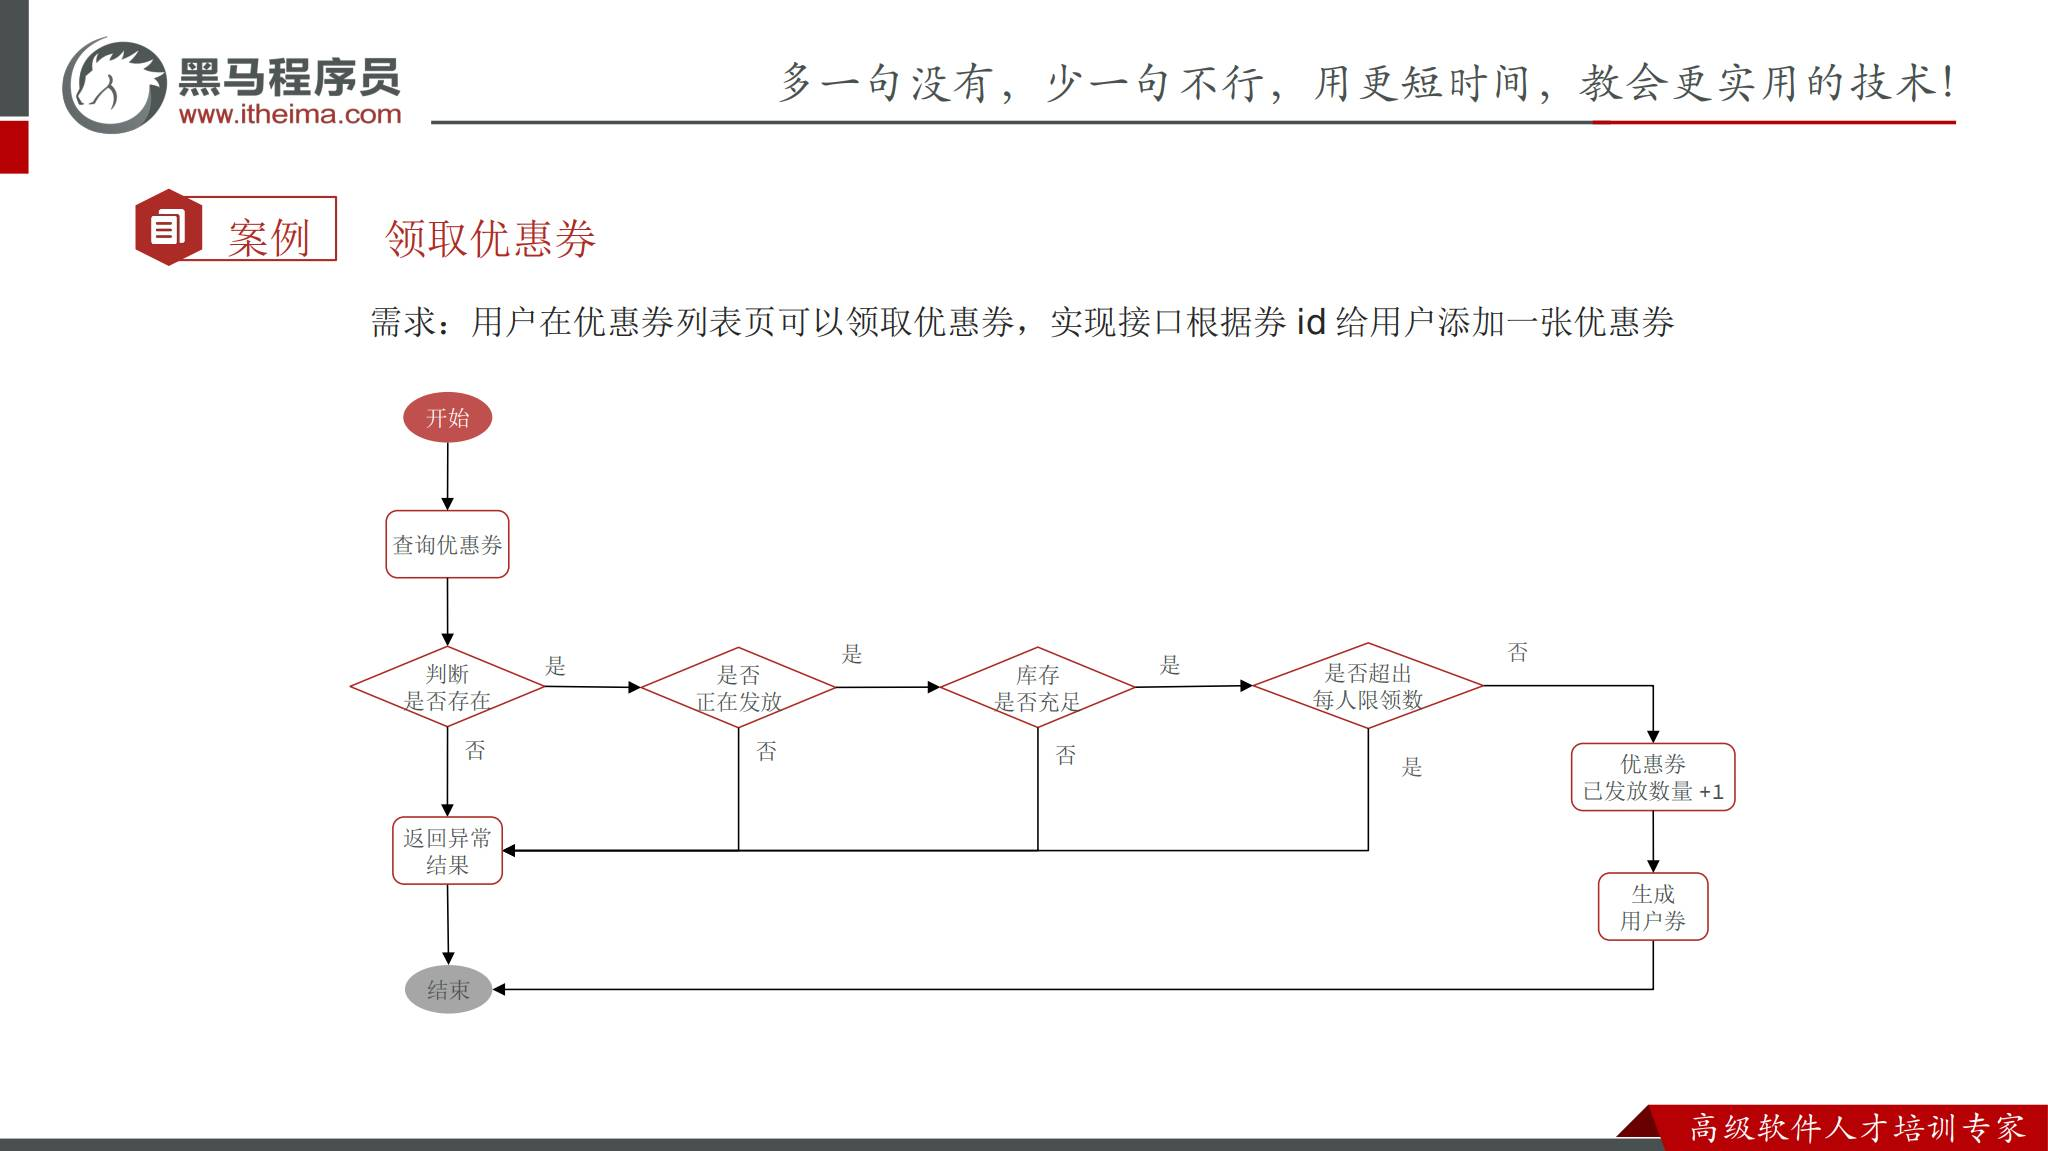

图源：网盘 `day10-领取优惠券.pptx` 第 14 页。图片随 Notebook 内嵌。

## 手动领取接口与用户券有效期

```java
@PostMapping("/{couponId}/receive")
public void receive(@PathVariable Long couponId) {
    userCouponService.receiveCoupon(couponId);
}
```

创建用户券时：

```java
LocalDateTime begin = coupon.getTermBeginTime();
LocalDateTime end = coupon.getTermEndTime();
if (begin == null) {                         // 领取后有效 N 天
    begin = now;
    end = begin.plusDays(coupon.getTermDays());
}
userCoupon.setTermBeginTime(begin);
userCoupon.setTermEndTime(end);
userCoupon.setStatus(UserCouponStatus.UNUSED);
```

发放中的检查要同时看 `status` 和时间窗口；手动接口还要确认领取方式是手动领取，避免用户拿着兑换码券的模板 ID 绕过兑换入口。统一时间区间推荐 `[issueBeginTime, issueEndTime)`：到结束时间即拒绝；原片段 `isAfter(end)` 允许等于结束时间，需要前后端统一。使用期限表单的 `termDays` 对应数据库 `term_days`，固定日期与有效天数二选一。

固定有效期应在配置阶段校验完整，不能把空的 `termEndTime` 写入 `NOT NULL` 字段。`now` 从本次事务中取一次；领取后 N 天按 `begin.plusDays(N)` 计算是课程方案，是否按自然日截止要另行定义。

## 兑换码领取的额外步骤

兑换接口是 `POST /user-coupons/{code}/exchange`，它没有优惠券 ID；解析兑换码得到序列号，再通过 `exchange_code.exchange_target_id` 找到模板。

```text
格式校验并解析 serial
  ↓
原子占用兑换标记
  ↓
查询 exchange_code，确认存在、未兑换、未过期
  ↓
查询 coupon，确认可发放、库存和用户限领
  ↓
创建 user_coupon，更新 issue_num
  ↓
更新 exchange_code 为已兑换
```

课程用 Redis Bitmap 的 `SETBIT` 返回旧值判断是否已经兑换：旧值为 1 就拒绝，旧值为 0 才继续。异常时课程示例会把 bit 重置为 0。原转载通过码查询券后直接进入公共方法，缺少券存在、发放状态 / 时间和库存等复核；整理实现必须补齐，否则暂停的兑换码券仍可能发券。

`exchange_code` 的真实字段是 `exchange_target_id`、`expired_time`，转载片段的 `getCouponId()` / `getExpireTime()` 与表结构不一致，应核对实体后分别调用 `getExchangeTargetId()` / `getExpiredTime()`。兑换流程的补偿不能误重置已提交成功的码。

## 兑换码与 Bitmap 的并发边界

`CodeUtil.parseCode` 只能证明兑换码结构和校验值正确，不能证明数据库里真的发行过这条码。兑换流程仍需查询 `exchange_code` 的目标券、状态和过期时间。

```redis
SETBIT coupon:code:used {serial} 1
```

Redis `SETBIT` 返回设置前的旧 bit，单条命令本身可以把“占用一个 bit”做成原子动作；但它与 MySQL 创建用户券不在同一个事务里：

| 顺序 | 可能故障 | 结果 |
| --- | --- | --- |
| 先置 bit，再写库 | 写库失败 | bit 卡住，需可靠补偿 |
| 先写库，再置 bit | 并发请求 | 两个请求可能都通过未使用检查 |
| 只依赖 Bitmap | Redis 丢失 | 已兑换码可能再次通过 |

Key 字符串为整理示例，已读转载只展示 `COUPON_CODE_MAP_KEY` 常量名。源方法把 `setBit` 返回的 `null` 当成 false；改进实现遇到空响应或超时应按结果未知处理，不能直接当作成功占位。

解析后先验证已发行序列，避免恶意输入让 Bitmap 分配巨大 offset。32 位完整空间最高占 512 MiB，高位稀疏标记也会扩展内存。若是先占位的课程顺序，则需严格校验序列上界、限流和监控。Bitmap 可以降低重复查询成本，但不能替代持久化状态。

## 查询我的优惠券

我的优惠券查询针对 `user_coupon`，不是 `coupon`。接口为 `GET /user-coupons/page`，参数是 `pageNo`、`pageSize`、可选 `status`；查询条件必须强制使用当前登录用户 ID。

```sql
SELECT id, coupon_id, term_begin_time, term_end_time,
       used_time, status
FROM user_coupon
WHERE user_id = :current_user
  AND (:status IS NULL OR status = :status)
ORDER BY create_time DESC, id DESC
LIMIT :offset, :page_size;
```

用户券列表通常展示未使用、已使用、已失效三个选项卡。过期状态可以由定时任务维护，或在查询时按统一时间规则计算有效状态。若采用结束时间不包含的约定，`UNUSED AND term_end_time <= now` 就是过期；未使用页同时过滤 `term_end_time > now`。不能先按旧状态分页再把其中几项改成“过期”，那样会造成选项卡、总数和列表错位。已使用记录仍展示为已使用，不因时间过去再改为过期。核销服务始终检查真实时间，不能只等定时任务更新状态。

## 超发为什么会出现

最初的实现是“查询 → 判断 → 更新”：线程 A 和线程 B 同时读到 `issue_num=99,total_num=100`，两者都判断库存充足，然后各自 `issue_num + 1`。如果更新语句没有条件，库存可能变成 101，用户券也多发出去。

共享资源的多行操作没有原子性，是典型的竞态。事务只能保证单个事务的原子提交，不能让两个事务之间的“读后判断”自动串行。需要把库存条件放进最终更新语句，让数据库在同一条语句中完成判断和占用。

## 悲观锁与乐观锁

| 方案 | 做法 | 优点 | 代价 |
| --- | --- | --- | --- |
| 悲观锁 | 进入临界区前先独占资源，其他线程等待 | 思路直接，保护范围明确 | 串行化，锁竞争会降低吞吐 |
| 乐观锁 | 不先加锁，更新时检查版本 / 旧值 / 库存条件 | 并发时不阻塞读取 | 竞争失败需要返回或重试 |

课件把最终方案称为“改进的乐观锁”：不要求 `issue_num` 等于刚才读取的旧值，而是在更新时直接判断还有库存。它更准确的名字是库存条件更新，条件表达业务不变量。

“不显式加应用锁”不等于 MySQL 不加锁。InnoDB 的 UPDATE 会对目标记录加写锁，并发请求仍会在同一券的计数行上竞争；优点是判断在数据库内完成，不需要把读出的旧值搬回来逐个 CAS。同批线程都读到旧值时普通 CAS 可能只有一个成功，但不是所有场景永远只有一个成功。

## 用条件更新解决库存超发

```sql
UPDATE coupon
SET issue_num = issue_num + 1
WHERE id = :coupon_id
  AND status = 3
  AND issue_num < total_num
  AND issue_begin_time <= :now AND issue_end_time > :now;
```

```java
int affected = couponMapper.incrIssueNum(couponId);
if (affected == 0) {
    throw new BizIllegalException("优惠券库存不足或已停止发放");
}
saveUserCoupon(coupon, userId);
```

课件最终 SQL 是 `WHERE id = :id AND issue_num < total_num`；这里额外加入状态和时间属于改进示例，防止读取模板后它被暂停 / 到期，仍按旧对象占库存。领取方式在事务校验和更新条件中配套限制。

`WHERE` 条件不满足不是 SQL 异常，而是影响行数为 0。必须检查返回值；否则代码会继续插入用户券，产生“用户券有了但库存没扣”的不一致。库存占用和用户券插入处于同一事务，插入返回失败也必须抛出异常，不要只检查是否抛出 SQL 异常。

## 库存条件更新仍需关注事务和对象新鲜度

条件更新只保护数据库计数，不会自动刷新内存中的 `Coupon` 对象。库存占用应以条件更新的影响行数作为最终结果；重新读取依然不能代替原子占用。不要在条件更新后继续使用旧对象推导库存。

```java
@Transactional(rollbackFor = Exception.class)
public void createUserCoupon(Coupon coupon, Long userId) {
    int affected = couponMapper.incrIssueNumIfAvailable(coupon.getId());
    if (affected != 1) throw new BizIllegalException("库存不足");
    // 后续 save 失败会让计数更新一起回滚
    if (userCouponMapper.insert(buildUserCoupon(coupon, userId)) != 1) {
        throw new DbException("创建用户券失败");
    }
}
```

如果数据库操作跨库、跨服务或通过消息完成，单个本地事务无法覆盖全部步骤，需要本地事务 + 可靠事件、补偿或库存预占状态。

## 用户限领是另一种并发问题

限领校验通常是：统计 `(user_id,coupon_id)` 的已有行数 → 判断是否达到 `user_limit` → 插入一行。即使库存条件更新安全，两个同一用户的请求仍可能同时看到旧数量，并都插入成功。

数据库唯一索引只适合“最多一张”的硬约束；`user_limit=2`、`3` 时需要保护一个可变计数或临界区。可选方案包括：

| 方案 | 适用条件 |
| --- | --- |
| 本机互斥锁 | 单实例或课堂实验；必须固定锁对象 |
| Redis / Redisson 分布式锁 | 多实例部署；要设置租约、续期和释放校验 |
| 用户券计数表 + 条件更新 | 把已领取数作为可更新资源，适合高并发 |
| 事务级数据库锁 | 以用户券计数行或用户行作为锁定对象 |

锁的键最好是 `couponId:userId`，否则同一用户领取不同优惠券也会被无意义地串行化。课程“只能用悲观锁”的表述针对当时的 COUNT 后 INSERT 实现；改成用户领取计数表之后，同样可以使用条件更新。

## 本机锁、对象身份和 `intern()`

课件示例使用：

```java
synchronized (userId.toString().intern()) {
    checkAndCreateUserCoupon(coupon, userId, null);
}
```

它要解决的教学问题是：`userId.toString()` 每次可能创建不同的 `String` 对象；相同内容用 `==` 不一定相同，锁就失效。`intern()` 可让相同字符串指向常量池对象。

相同字符串调用 `intern()` 得到同一引用，但不能把字符串池当成业务锁管理器：大量用户键会增加池查找和内存压力，而且只在单 JVM 内生效。现代 JVM 对可达性和回收的处理不等于“所有 intern 字符串永远不能回收”。

单机改进可以用固定数量的条带锁，以组合键散列到同一把 `ReentrantLock`，允许少量无关键竞争。随便使用会过期淘汰的锁缓存有隐患：旧锁仍被占用时，缓存淘汰后新建另一把锁又会破坏互斥。生产多实例使用分布式锁或数据库计数，所有入口必须采用同一方案。

## 锁的边界必须包住已提交事务

第一次加锁仍超领，常见原因是事务边界比锁更大：

```text
线程 1：开启事务 → 获取锁 → 查询 / 插入 → 释放锁 → 提交事务
线程 2：开启事务 → 等待锁 → 获取锁 → 查询
```

在线程 1 释放锁时，插入还未提交；线程 2 在默认隔离级别下读不到未提交行，于是错误地认为用户还没领过。

正确关系是：

```text
获取锁 → 开启事务 → 查询、判断、库存更新、插入 → 提交事务 → 释放锁
```

把锁放到事务外，把真正的事务方法放到由 Spring 代理调用的 `public` 方法中。锁释放发生在提交之后，后一个线程读取到的才是前一个线程已经确认成功的结果。若后一个事务在拿锁前已做过一致性读，可重复读隔离级别还可能保留旧快照；从取锁之后开始这个事务，避免继承旧读视图。

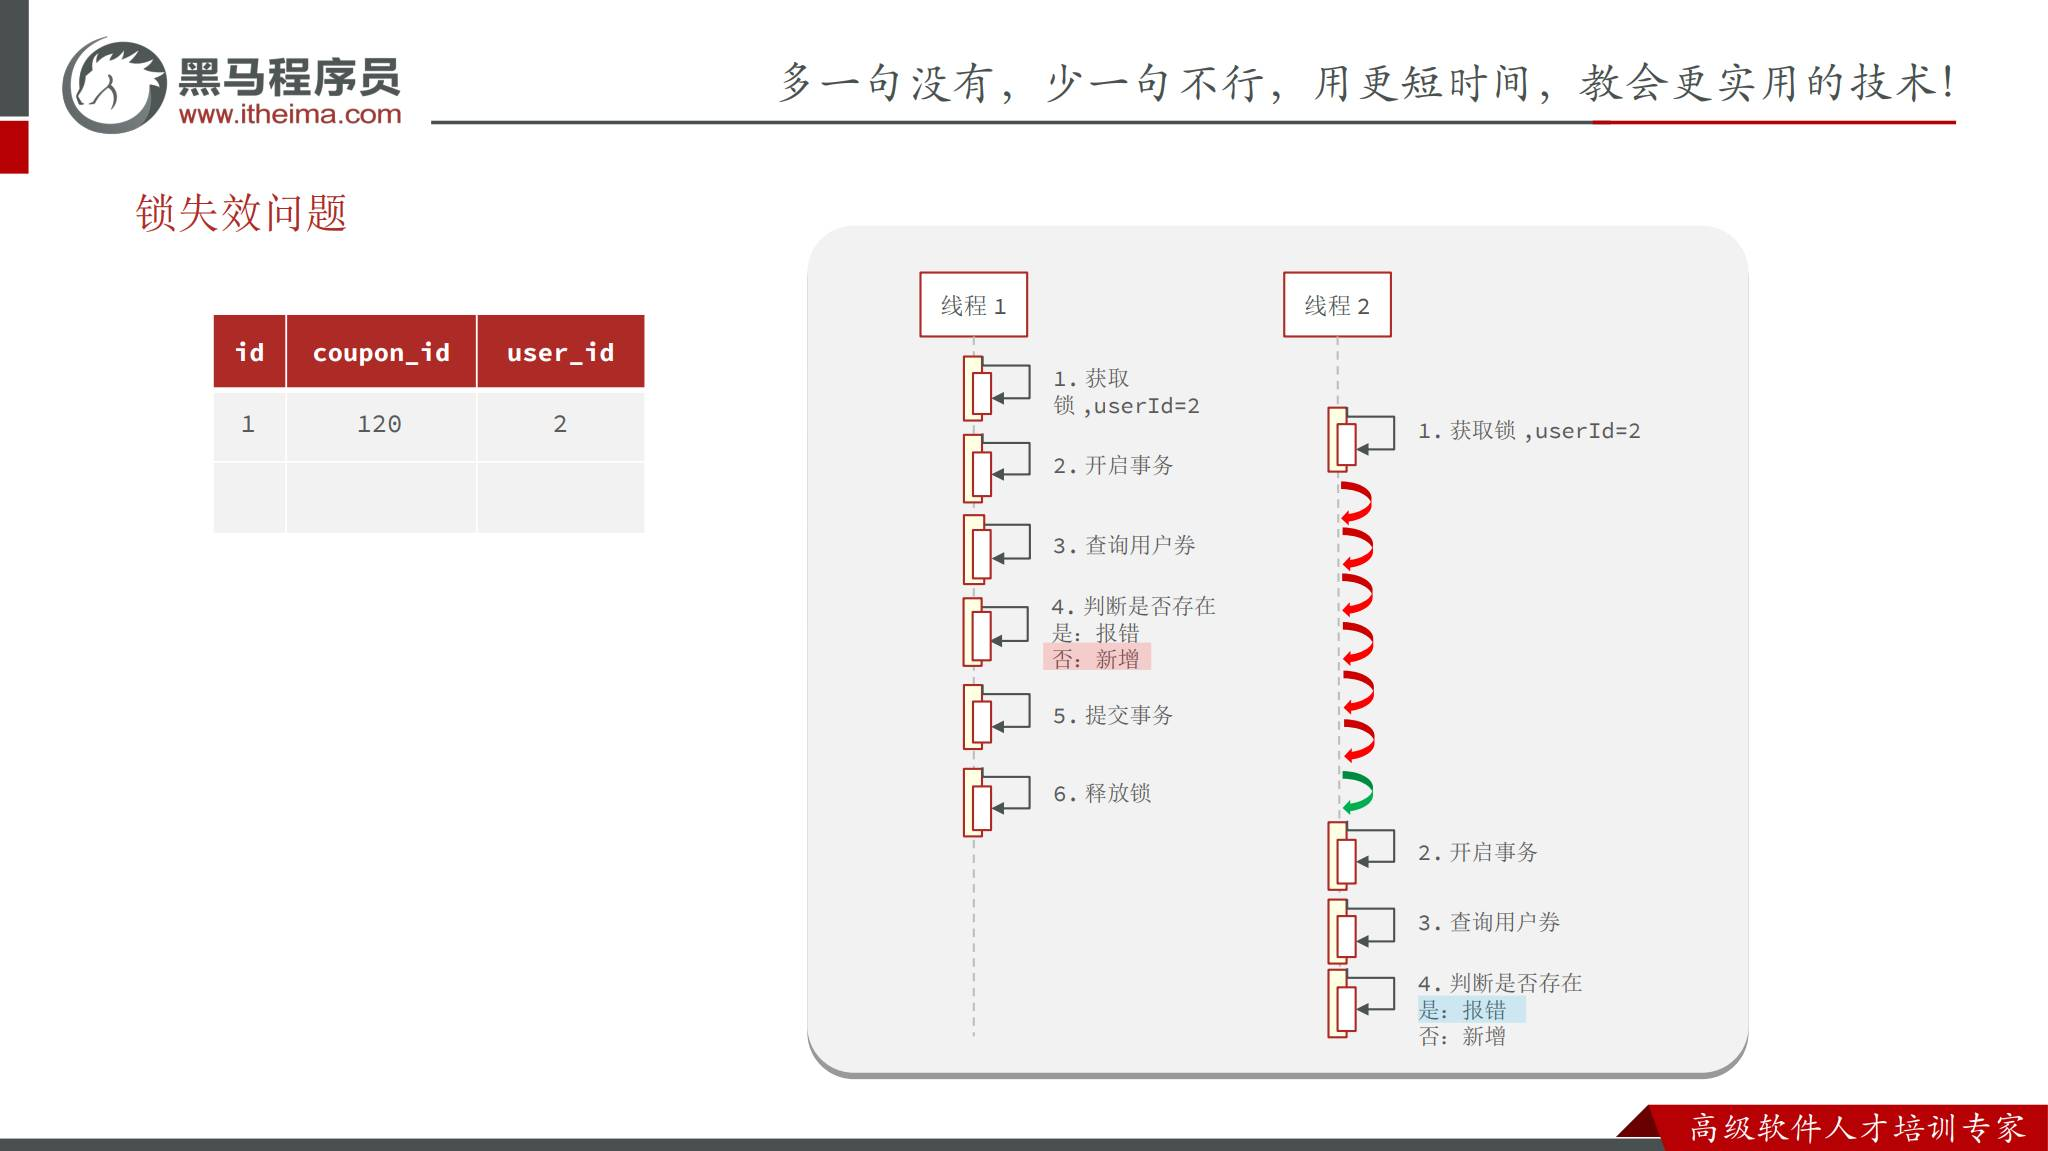

图源：网盘 `day10-领取优惠券.pptx` 第 32 页。图片随 Notebook 内嵌。

## 事务方法的组织方式

课件把 `checkAndCreateUserCoupon` 抽成一个 `public` 事务方法，外层 `receiveCoupon` 负责获取用户锁，再调用它。这样事务边界位于锁内部，同时满足 Spring 代理的要求。

```java
public void receiveCoupon(Long couponId) {
    Long userId = UserContext.getUser();
    String key = couponId + ":" + userId;
    try (LockHandle ignored = lock(key)) {
        couponTxService.checkAndCreateUserCoupon(couponId, userId, null);
    }
}

@Transactional(rollbackFor = Exception.class)
public void checkAndCreateUserCoupon(Long couponId, Long userId, Long serial) {
    // 限领查询、条件占库存、插入 user_coupon、更新兑换码
}
```

这是结构伪代码，`LockHandle` / `lock(key)` 为“取得并在 finally 释放锁”的占位封装，不是课程附件 API。`couponTxService` 是另一个 Spring Bean，事务中重新查询模板、领取次数并校验；不能沿用锁前的模板快照决定全部资格。私有 `saveUserCoupon` 作为已开启事务中的普通辅助方法可正常参与事务，无需单独标注事务。

外层必须确实没有活动事务；内层默认 `REQUIRED` 若加入上层未提交事务，方法返回时仍不提交，锁外事务问题又会出现。限定调用入口，或用清楚的事务传播设计 / `TransactionTemplate` 让这段操作拥有确定的提交边界。提交错误和业务异常都会在事务代理返回前抛出，锁在其后释放。

## 兑换码流程的事务补偿

兑换码不仅要创建用户券，还要把 `exchange_code` 绑定到用户并改成已兑换。课程示例中先用 Bitmap 占位，失败时重置；如果希望数据库作权威，建议用条件更新：

```sql
UPDATE exchange_code
SET status = 2, user_id = :user_id, update_time = NOW()
WHERE id = :serial AND status = 1 AND expired_time > NOW();
```

只有影响行数为 1 才继续创建用户券。若用户券创建失败，事务回滚数据库状态；Bitmap 只在提交后异步更新，或由补偿任务从数据库重建。若必须先占 Bitmap，要为“占用中、成功、失败待恢复”设计持久状态，不能简单把 bit 盲目改回 0。

## 为什么 `catch` 重置兑换 bit 仍不够

课程的 `exchangeCoupon` 标注事务，在方法内部 `try/catch`：先置 bit，异常时清零并重新抛出。这可以演示普通业务异常的补偿，但覆盖不了所有提交结果。

```text
方法体完成 → Spring 事务代理提交数据库 → 提交成功或抛出异常 → 返回外层
              ↑ 提交失败发生在方法体外，内部 catch 不能捕获
```

| 故障 | 内部 catch 能否可靠处理 | 所需恢复 |
| --- | --- | --- |
| 方法体内数据库写失败 | 能捕获业务异常，但清零也可能失败 | 持久任务记录；数据库回滚后再判定恢复 |
| 方法体结束后提交失败 | 不能由该方法内部 catch 捕获 | 外层确认回滚 / 结果未知后对账 |
| 进程在置 bit 后崩溃 | 不能 | 扫描占用任务，依据数据库发行 / 兑换状态修复 |
| 提交已成功，客户端超时重试 | 无法只靠异常判断 | 按兑换序列和用户查成功记录，幂等返回 |

不要在数据库结果未知时无条件清零，也不能让失败线程清掉另一次尝试的占位。推荐数据库条件更新与发券同事务；成功后同步 bit 失败只影响缓存，由重建任务处理，不影响已确认兑换结果。

## Spring 事务失效的第一组原因

事务依赖 Spring AOP 代理。下面情况会让 `@Transactional` 看起来存在，实际上没有创建有效事务：

| 原因 | 为什么失效 | 修复思路 |
| --- | --- | --- |
| 方法不是 `public` | 课程使用的代理 / 事务配置只增强公有入口 | 按课程配置使用 `public` 事务入口 |
| 非事务方法调用同类事务方法 | `this.method()` 走原对象，不经过代理 | 抽到另一个 Bean，或通过代理调用 |
| 对象没有被 Spring 管理 | 未注册 Bean，或用 `new` 创建了另一对象 | 用 `@Service` / `@Bean` 注册并通过容器注入 |
| 事务异常被捕获后吞掉 | 代理看不到异常，无法回滚 | 记录后重新抛出，或显式标记回滚 |

“加了注解”只是声明意图，真正生效还取决于调用路径是否经过代理，以及异常是否传播到事务拦截器。`public` 约束是课程环境的结论；新版 Spring 配合类代理可支持部分非公有方法，不能把它当作所有版本的绝对规则。私有方法和自调用依然无法按普通代理方式增强。

## Spring 事务失效的第二组原因

| 原因 | 典型表现 | 处理方式 |
| --- | --- | --- |
| 异常类型不匹配 | 默认对 `RuntimeException` 和 `Error` 回滚，checked exception 默认不回滚 | `@Transactional(rollbackFor = Exception.class)`，按业务选择 |
| 传播行为不当 | 内层 `REQUIRES_NEW` 独立提交，外层回滚也影响不到它 | 明确外层与内层事务的独立性，慎用新事务 |
| 无法代理的方法 | 私有 / final 方法无法按预期被类代理增强 | 让可代理的公有方法成为事务边界 |
| 事务覆盖范围错误 | 锁已释放、异步已执行，事务还没提交 | 重新安排锁、事务、任务的顺序 |

`rollbackFor` 不能解决跨服务写入的一致性，也不能让 Bitmap 与 MySQL 自动共享事务。它只告诉当前事务拦截器遇到指定异常时回滚本地资源。课件的传播示例把 `reduceStock()` 写在同类中；原样自调用不会应用新的 `REQUIRES_NEW`。只有经过另一个代理 Bean 调用时，才会挂起外部事务、独立提交 / 回滚。这个独立事务不是能随外层一起回滚的“子事务”。

## 回滚失败与“异常已经被处理”的区别

异常被业务代码捕获，不代表事务一定可以提交。若事务已经被底层或内层代理标记为 `rollback-only`，外层即使捕获异常，提交仍会回滚，可能抛出 `UnexpectedRollbackException`。若异常被吞掉且没有回滚标记，事务则可能把部分业务写入提交出去。

```java
@Transactional(rollbackFor = Exception.class)
public void grant() {
    try {
        insertUserCoupon();
    } catch (RuntimeException e) {
        log.error("发券失败", e);
        throw e; // 让代理知道本次业务失败，不伪装成功
    }
}
```

当决定回滚时，应抛出业务异常或按确切需求显式标记回滚；不要只打印日志继续返回“领取成功”。数据库提交超时还可能是结果未知，重试前查询幂等记录。幂等与事务解决的是两个问题：事务保障一次提交的一致性，幂等保障多次重试不会重复产生结果。

## 用代理对象修复自调用

课件给出的技术路线是引入 AspectJ、在启动类设置 `@EnableAspectJAutoProxy(exposeProxy = true)`，再通过 `AopContext.currentProxy()` 获取当前代理调用事务方法：

```java
@SpringBootApplication
@EnableAspectJAutoProxy(exposeProxy = true)
public class PromotionApplication {}

IUserCouponService proxy = (IUserCouponService) AopContext.currentProxy();
proxy.checkAndCreateUserCoupon(coupon, userId, serialNum);
```

**补充 / 改进示例**：优先把事务逻辑抽到独立的 `CouponReceiveTxService`，由外层服务注入调用，代码更容易测试，也不依赖线程上下文中的当前代理。课程配置采用公有事务入口，Bean 必须由 Spring 管理。

`aspectjweaver` 依赖加 `@EnableAspectJAutoProxy` 是代理 AOP 的课程配置，不等于已经启用 AspectJ 编译期 / 加载期织入，也不会让任意 `this` 调用自动受事务增强。`AopContext.currentProxy()` 需要本线程正在经过被暴露的代理调用；在普通新线程或非代理入口里无法凭空取得它。

## 单机完整边界示例：固定条带锁与独立事务 Bean

看到注解与同步块时，先沿实际调用路径确认顺序。下面是 Java 11 的单机结构示例，重点是事务提交后才解锁。条带锁集合不能每个服务实例各自创建，须由同 JVM 中所有入口共享。

```java
// 外层 Bean 无 @Transactional，调用方也不能包住它另开事务
private static final ReentrantLock[] LOCKS = new ReentrantLock[256];
static {
    for (int i = 0; i < LOCKS.length; i++) LOCKS[i] = new ReentrantLock();
}

public void receiveCoupon(Long couponId) {
    Long userId = UserContext.getUser();
    if (userId == null) throw new BizIllegalException("请先登录");
    int index = Math.floorMod(Objects.hash(couponId, userId), LOCKS.length);
    ReentrantLock lock = LOCKS[index];
    lock.lock();
    try {
        // 这是另一个注入的 Spring Bean；返回时其事务已提交
        receiveTxService.receive(couponId, userId);
    } finally {
        lock.unlock();
    }
}
```

另一个 Bean 的事务主线：

```java
@Transactional(rollbackFor = Exception.class)
public void receive(Long couponId, Long userId) {
    Coupon c = couponMapper.selectById(couponId);
    LocalDateTime now = LocalDateTime.now();
    validatePublicCoupon(c, now); // 存在、手动领取、进行中、时间与期限
    long count = userCouponMapper.selectCount(new LambdaQueryWrapper<UserCoupon>()
        .eq(UserCoupon::getUserId, userId).eq(UserCoupon::getCouponId, couponId));
    if (count >= c.getUserLimit()) throw new BizIllegalException("达到领取上限");
    if (couponMapper.incrIssueNumIfAvailable(couponId, now) != 1) {
        throw new BizIllegalException("库存不足或停止发放");
    }
    if (userCouponMapper.insert(buildUserCoupon(c, userId, now)) != 1) {
        throw new DbException("创建用户券失败");
    }
}
```

`validatePublicCoupon`、`buildUserCoupon` 和 Mapper 条件更新是前文规则的封装，示例省略 imports 和构造器。兑换入口同样获取组合键锁后进入事务，并额外在事务中条件更新兑换码。多实例不共享 `LOCKS`，部署多个副本时必须替换保护机制，数据库库存条件仍然保留。

## 数据库约束与并发策略的配合

并发安全通常不是只选一个锁，而是让每个约束由合适的原子操作负责：

| 约束 | 推荐原子操作 | 失败结果 |
| --- | --- | --- |
| 模板库存 | `UPDATE ... issue_num < total_num` | 影响行数 0，返回库存不足 |
| 单用户限领 | `couponId:userId` 锁 + 事务内查询插入，或用户券计数条件更新 | 达到上限，回滚本次操作 |
| 兑换码一次性 | `UPDATE exchange_code ... status=1` 条件更新 | 影响行数 0，已兑换 / 过期 |
| 用户券状态 | `UPDATE user_coupon ... status=1` 条件更新 | 已使用或已失效，拒绝核销 |

缓存里的 `available`、列表里的 `received` 和前端按钮都只是提示。最终决定权应落在数据库条件更新或同等可靠的原子资源上。

## 多实例的限领约束怎样落在数据库

本地锁不能跨 JVM 保护临界区。Redisson 可让多个实例共用同一键锁，但网络、超时和租约失效仍需处理；更强的持久约束是把用户领取数保存为可原子更新的计数行。

```sql
-- 改进思路：新增计数表，唯一键 (user_id, coupon_id)
UPDATE user_coupon_quota
SET received_num = received_num + 1
WHERE user_id = :user_id AND coupon_id = :coupon_id
  AND received_num < :user_limit;
```

计数行创建也必须幂等，先通过唯一键的插入 / upsert 确保存在，不能再做无保护的“先查有没有、再建行”。这条更新、模板库存更新、用户券插入处于同一本地事务；任一步失败都回滚。历史用户券要先回填计数，所有领取入口和重试路径都同步计数，否则会发生双份事实不一致。

这是扩展设计，不是本章已读取的课程建表方案。第 11 章再展开高并发领取优化；这里先明确单机锁的适用条件，避免把课堂代码直接当成多副本保证。

## JMeter 并发测试资料

课程资料的 `jmeter` 目录包含 JMeter 5.4.1 压缩包、`领取优惠券.jmx` 测试脚本、`userInfo.txt` 用户信息、`exchangeCode.txt` 兑换码数据和入门 Markdown。转载讲义称用户信息为虚拟测试数据，并展示了 100 张库存被发出 109 张的课堂超卖结果，不是本次压测数据。

测试设计至少要区分：

| 场景 | 观察指标 |
| --- | --- |
| 多用户抢同一张券 | `issue_num`、`user_coupon` 行数是否超过 `total_num` |
| 同一用户并发领取 | 该用户的行数是否超过 `user_limit` |
| 同一码并发兑换 | 只有一个用户券成功、兑换码只有一次成功绑定 |
| 失败后重试 | 库存计数、用户券、兑换码状态是否能一起恢复 |

本章只记录测试方法和应验证的约束，没有运行压测脚本，也没有使用资料中的虚拟账号或兑换码。

## 压测配置和结果判断

能重复复现竞态，才能证明改动保护了对应约束。课程示例可导入 `领取优惠券.jmx`，重新选择本机 CSV 文件路径，再检查请求目标和变量绑定。附件完整脚本未读取，以下是通用操作要点。

| 配置 | 多用户抢库存 | 单用户验证限领 |
| --- | --- | --- |
| 线程与数据 | 并发线程分别使用不同测试身份 | 多线程使用同一个测试身份 |
| 目标券 | 相同 couponId，库存小于请求总数 | 相同 couponId，限领 1 或 2 |
| 前置状态 | 窗口有效、手动券、库存足够复现 | 留足库存，排除库存不足干扰 |
| 断言 | HTTP 状态 + 业务响应表示真正成功 | 同样区分业务拒绝和请求成功 |

CSV Data Set Config 的循环、EOF 停止和共享方式会影响是否实际复用了身份。只看 HTTP 200 或平均延迟不足以验证正确性，项目响应包装可能在 200 中返回业务错误。测试后按本次目标券核对 `issue_num`、实际用户券行数、每用户数量和兑换码状态；为提交失败 / 插入异常注入故障，验证回滚。测试数据准备和清理只在隔离环境操作。

## 我的优惠券练习

课件练习要求完成 `GET /user-coupons/page`：

1. 从 `UserContext` 获取当前用户，不能让请求参数覆盖它；
2. 用 `pageNo`、`pageSize` 转成 MyBatis-Plus 分页；
3. `status` 为空时查全部，非空时只查该状态；
4. 以 `create_time` 或用户券 ID 倒序，保证翻页稳定；
5. 返回用户券展示所需字段，必要时关联优惠券规则，但避免每行一次关联查询；
6. 对过期用户券统一按有效期规则处理，过期枚举符号以实际 `UserCouponStatus` 为准。

如果列表需要名称和优惠说明，可先分页查用户券，再用 `coupon_id` 批量查模板并在内存中组装 VO。不要把模板表当成用户持有表直接查询。

## 兑换码功能的改造练习

手动领取经过库存条件更新和用户锁后，兑换码流程也要达到相同的安全级别：

```text
解析码 → 原子占用 / 条件更新兑换码
      → 获取 couponId
      → 使用同一套库存与限领事务服务
      → 成功后确认兑换码已绑定用户
```

不要复制一份“检查库存、检查限领、插入用户券”的代码；让手动领券和兑换码领券共用同一个事务服务。兑换码只是资格来源不同，用户券创建和库存占用必须采用同一套原子规则。

## 练习：优惠券即将过期提醒

领取后未使用的券需要及时提醒。课程要求设计过期前短信提醒方案，没有指定完整实现；下面是方案笔记，不实际发送短信。

```text
XXL-JOB 分片扫描到期窗口内的 UNUSED 用户券
  ↓
创建提醒记录（唯一键：userCouponId + 提醒类型 + 到期版本）
  ↓
事务提交后通过可靠任务 / 消息发送提醒
  ↓
短信成功记录回执，失败有限重试，永久失败可见
```

| 关键点 | 处理 |
| --- | --- |
| 查询窗口 | 例如未来 24 小时内，配索引 `(status,term_end_time,id)`；用游标批量读取 |
| 定时重复执行 | 提醒记录唯一键去重，不能每次扫描都发送 |
| 发送前券已使用 | 再检查 UNUSED 和未过期，跳过无需提醒的券 |
| 手机号码与模板 | 使用用户通知服务和批准模板；日志只记录必要的任务标识 |
| 发送失败 / 超时 | 记录待重试和回执；供应商幂等能力避免重复短信 |
| 用户通知偏好 | 尊重退订、发送时段及必要的频率限制 |

扫描窗口、24 小时、表和任务状态均为改进设计示例。短信属于外部副作用，数据库事务不能撤销已经发出的短信，所以以可靠任务和幂等回执协调。

## 事务与锁的常见错误定位顺序

发生超领或库存不一致时，可按以下顺序定位：

1. 看数据库最终计数和用户券行数，确认是库存超发、限领超发，还是补偿重复；
2. 打开 SQL 日志，确认库存更新带有 `issue_num < total_num`，并检查影响行数；
3. 检查同一用户锁的键是否一致，单机锁是否误用于多实例；
4. 对照时间线，确认锁释放发生在事务提交之后；
5. 检查事务入口是否为 `public`、Bean 是否受 Spring 管理、调用是否经过代理；
6. 检查异常是否被吞掉、是否属于回滚类型、是否使用了 `REQUIRES_NEW`；
7. 对兑换码检查 Bitmap、数据库状态和补偿任务是否出现分叉。

先确定违反了哪个业务不变量，再选择锁或事务修复，避免只增加 `synchronized` 却保留错误的边界。

## 本章要点对照

| 主题 | 需要记住的结论 |
| --- | --- |
| 用户券 | 模板券属于运营配置，用户券才属于用户并记录使用状态 |
| 匿名列表 | `/coupons/list` 可放行，列表展示状态不能替代领券校验 |
| 手动领取 | 检查进行中、库存和限领，再原子占库存并创建用户券 |
| 兑换码 | 解析码只做结构验证，仍要查发行记录、目标券、过期和资格 |
| 超卖 | `UPDATE ... WHERE issue_num < total_num`，并检查影响行数 |
| 超领 | 锁定组合键或使用分布式 / 条件计数，锁必须覆盖已提交事务 |
| 事务失效 | 代理、自调用、异常类型、传播行为和 Bean 管理都会影响回滚 |

前文练习和业务表对应三种不变量：`issue_num <= total_num`、每用户累计领取数 `<= user_limit`、每个兑换序列最多关联一次成功发券。幂等是指相同业务请求重试不会产生第二份结果；同时支持合法多次领取时，请求 ID 需要与一次领取尝试绑定，不能简单把 `couponId:userId` 全部请求判为同一次。

**面试提示**：回答“如何防止优惠券超发”时，要把库存约束和用户限领拆开。库存用数据库条件更新，限领需要保护“查询 + 判断 + 插入”的整体边界；如果还有兑换码，再补充一次性兑换状态和失败补偿。

## 材料差异与实现边界

| 课件 / 转载中的简化 | 本章的整理说明 |
| --- | --- |
| 列表代码直接从 `UserContext.getUser()` 查询 | 匿名访问时要处理空用户，不能让未登录列表报错 |
| 领券代码先查询库存再普通更新 | 这会超发；采用条件更新并检查影响行数 |
| 本机 `userId.toString().intern()` 锁 | 只能解决单 JVM 的教学示例，生产多实例要用分布式锁或条件计数 |
| Bitmap 先占位，异常时重置 | 与 MySQL 没有原子事务，需幂等状态、条件更新和恢复任务 |
| 事务方法在同类内部调用 | 会绕过代理；独立 Bean 或暴露代理调用 |
| `REQUIRES_NEW` 作为普通内层事务 | 外层回滚不能撤销独立提交，必须明确传播意图 |
| 示例 Java 有缺失括号、旧字段名等笔误 | 只保留业务约束，未把转载代码原样当作可编译源码 |

附件目录与转载页面还包含前端截图、VO、枚举和 JMeter 资料；本次未取得完整 Java / SQL / 压测附件，也未取得 JMeter Markdown 正文，没有把它们当作已读源码引用。

## 业务验证场景

以下是复现工程后要核对的结果，不是本次已执行的课程测试。

| 输入 / 故障 | 预期 |
| --- | --- |
| 未登录浏览 `/coupons/list` | 返回公开券列表，用户领取计数按空处理 |
| 未登录领取、兑换或查私人列表 | 拒绝；不写入用户券 |
| 手动接口传兑换码券 ID | 拒绝，不能绕过码校验 |
| 暂停券、未开始券、领取结束时间恰好到达 | 拒绝领取 / 兑换 |
| 1 个库存，多个不同用户同时领取 | 只产生 1 次成功占库存和 1 张用户券 |
| 限领 1，同一用户并发领取 | 最多成功 1 次；其他事务看到提交后的计数 |
| 已使用 / 已失效的券再次尝试领取 | 仍占累计限领额度；按规则拒绝或允许剩余额度 |
| 同一码由两用户提交 | 数据库只允许 1 次 USED 迁移和 1 张用户券 |
| 同一用户用不同码领取同一模板 | 同样受用户限领约束 |
| 用户券插入失败 | 库存占用与兑换码迁移一并回滚 |
| 提交成功但响应丢失 | 通过请求 / 兑换记录认出成功，重试不多发 |
| Redis 占位后崩溃或 Redis 数据丢失 | 对账恢复，数据库已兑换码不会再成功发券 |
| 查我的优惠券时伪造 userId | 查询仍只用登录身份，不返回他人的券 |
| 提醒任务重复扫描 / 消费 | 同一提醒事件不会重复发送 |

观察值同时核对用户券记录、模板计数、兑换码归属和失败任务。只验证页面按钮或接口响应无法证明这些不变量成立。

## 面试提示

**面试提示**：优惠券领取至少有四个独立问题：列表是否展示、模板库存是否足够、用户是否超过限领、兑换码是否已被使用。展示字段只是提示，真正写入时必须重新检查。

库存超发用数据库的条件更新把判断和加一放进一条 SQL；限领校验要锁定 `couponId:userId`，并让锁覆盖到事务提交。兑换码可以用 Bitmap 做快速占位，但数据库状态、用户券和库存仍要设计幂等与补偿。

Spring 事务失效先查代理链路，再查异常和传播行为。`@Transactional` 标在一个方法上，不代表所有调用路径都会经过它。